# Install Library

In [ ]:
!pip install sentence-transformers -q

# Import Libraries

In [ ]:
from datasets import load_dataset, concatenate_datasets
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd

# Load Dataset

In [ ]:
swefaq_corpus = load_dataset("mteb/SweFaqRetrieval", "corpus")["test"]
swefaq_queries = load_dataset("mteb/SweFaqRetrieval", "queries")["test"]
swefaq_qrels = load_dataset("mteb/SweFaqRetrieval", "qrels")["test"]

splits = ["train", "validation", "test"]
all_corpus, all_queries, all_qrels = [], [], []
for split in splits:
    corpus_split = load_dataset("mteb/SwednRetrieval", "corpus")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    queries_split = load_dataset("mteb/SwednRetrieval", "queries")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    qrels_split = load_dataset("mteb/SwednRetrieval", "qrels")[split].map(lambda x: {
        "query-id": f"{split}_{x['query-id']}", "corpus-id": f"{split}_{x['corpus-id']}"
    })
    all_corpus.append(corpus_split); all_queries.append(queries_split); all_qrels.append(qrels_split)

swedn_corpus = concatenate_datasets(all_corpus)
swedn_queries = concatenate_datasets(all_queries)
swedn_qrels = concatenate_datasets(all_qrels)

def build_qrels_dict(qrels):
    d = {}
    for row in qrels:
        d.setdefault(row["query-id"], set()).add(row["corpus-id"])
    return d

swefaq_qrels_dict = build_qrels_dict(swefaq_qrels)
swedn_qrels_dict = build_qrels_dict(swedn_qrels)

README.md:   0%|          | 0.00/6.41k [00:00<?, ?B/s]

corpus/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 88.9kB            

corpus/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/511 [00:00<?, ? examples/s]

queries/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.5kB            

...

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

Map:   0%|          | 0/2046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

# Load Model

In [ ]:
model = SentenceTransformer("intfloat/multilingual-e5-base")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:01<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

# Long-Document Truncation Check

Dense models have a maximum input token limit, so very long documents may be truncated.

In this check, we estimate document token counts using approximately 1.3 tokens per Swedish word and compare them with the model's maximum sequence length. We then calculate the percentage of SwednRetrieval documents that may exceed this limit.

This helps us identify whether dense retrieval may miss information from long documents, unlike BM25, which can search the full document text.

In [ ]:
max_seq_length = model.max_seq_length
print("Model max sequence length (tokens):", max_seq_length)

# Approximate: average 1 word ≈ 1.3 tokens Swedish-e
swedn_word_counts = [len(doc["text"].split()) for doc in swedn_corpus]
over_limit = sum(1 for w in swedn_word_counts if w * 1.3 > max_seq_length)
print(f"SwdnRetrieval: Documents likely exceeding model limit: {over_limit} / {len(swedn_corpus)} ({100*over_limit/len(swedn_corpus):.1f}%)")



swefaq_word_counts = [len(doc["text"].split()) for doc in swefaq_corpus]
swefaq_over_limit = sum(1 for w in swefaq_word_counts if w * 1.3 > max_seq_length)
print(f"SweFAQ: Documents likely exceeding model limit: {swefaq_over_limit} / {len(swefaq_corpus)} ({100*swefaq_over_limit/len(swefaq_corpus):.1f}%)")

Model max sequence length (tokens): 512
SwdnRetrieval: Documents likely exceeding model limit: 2060 / 6141 (33.5%)
SweFAQ: Documents likely exceeding model limit: 0 / 511 (0.0%)


# Embedding SwednRetrieval documents (full corpus, truncated)

Before chunking, we also build embeddings for the *full* (truncated) document text. This lets us compare "truncated" vs "chunked" dense retrieval later, to see how much truncation actually costs us.

### Embedding full corpus

In [ ]:
swedn_corpus_ids = [doc["_id"] for doc in swedn_corpus]
swedn_corpus_texts = ["passage: " + doc["text"] for doc in swedn_corpus]

swedn_embeddings = model.encode(
    swedn_corpus_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True
)
print("SwednRetrieval (truncated) embeddings shape:", swedn_embeddings.shape)

Batches:   0%|          | 0/96 [00:00<?, ?it/s]

SwednRetrieval (truncated) embeddings shape: (6141, 768)


### Document Chunking in SwednRetrival

Long documents are split into smaller, overlapping chunks of around 500 words to preserve context. Each chunk gets its own embedding. For a query, we compare it with all chunk embeddings and use the highest-scoring chunk as the document's relevance score.

In [ ]:
def chunk_text(text, chunk_size=400, overlap=50):
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    chunks = []
    start = 0
    while start < len(words):
        end = start + chunk_size
        chunk = " ".join(words[start:end])
        chunks.append(chunk)
        start += chunk_size - overlap
    return chunks

In [ ]:
def build_chunked_corpus(corpus):
    chunked_ids = []       # chunked document id
    chunked_texts = []
    parent_ids = []        # original document id

    for doc in corpus:
        doc_id = doc["_id"]
        chunks = chunk_text(doc["text"])
        for i, chunk in enumerate(chunks):
            chunked_ids.append(f"{doc_id}_chunk{i}")
            chunked_texts.append(chunk)
            parent_ids.append(doc_id)

    return chunked_ids, chunked_texts, parent_ids

swedn_chunk_ids, swedn_chunk_texts, swedn_parent_ids = build_chunked_corpus(swedn_corpus)
print(f"Original documents: {len(swedn_corpus)} → Chunks: {len(swedn_chunk_ids)}")

Original documents: 6141 → Chunks: 10136


### Embedding chunked documents

In [ ]:
chunk_passages = ["passage: " + t for t in swedn_chunk_texts]
swedn_chunk_embeddings = model.encode(chunk_passages, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

Batches:   0%|          | 0/159 [00:00<?, ?it/s]

In [ ]:
def search_dense_chunked(query_text, model, chunk_embeddings, parent_ids, top_k=10):
    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    scores = (chunk_embeddings @ query_emb.T).flatten()
    doc_best_score = {}
    for score, pid in zip(scores, parent_ids):
        if pid not in doc_best_score or score > doc_best_score[pid]:
            doc_best_score[pid] = score
    ranked = sorted(doc_best_score.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return [d for d, s in ranked]



# Embedding SweFAQ documents

In [ ]:
swefaq_corpus_ids = [doc["_id"] for doc in swefaq_corpus]
swefaq_corpus_texts = ["passage: " + doc["text"] for doc in swefaq_corpus]

swefaq_embeddings = model.encode(
    swefaq_corpus_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True
)
print("SweFAQ embeddings shape:", swefaq_embeddings.shape)

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

SweFAQ embeddings shape: (511, 768)


In [ ]:
def search_dense(query_text, model, corpus_embeddings, corpus_ids, top_k=10):
    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    scores = (corpus_embeddings @ query_emb.T).flatten()
    top_indices = scores.argsort()[::-1][:top_k]
    return [corpus_ids[i] for i in top_indices]

# Evaluate Function

In [ ]:
def recall_at_k(retrieved_ids, relevant_ids, k):
    top_k = set(retrieved_ids[:k])
    if len(relevant_ids) == 0:
        return None
    return len(top_k & relevant_ids) / len(relevant_ids)

def ndcg_at_k(retrieved_ids, relevant_ids, k):
    dcg = sum(1/np.log2(i+2) for i, d in enumerate(retrieved_ids[:k]) if d in relevant_ids)
    ideal_hits = min(len(relevant_ids), k)
    idcg = sum(1/np.log2(i+2) for i in range(ideal_hits))
    return dcg/idcg if idcg > 0 else None

def evaluate_retrieval(search_fn, queries, qrels_dict, k_values=[1,3,10]):
    results = {f"Recall@{k}": [] for k in k_values}
    results["nDCG@10"] = []
    for q in queries:
        qid = q["_id"]
        if qid not in qrels_dict:
            continue
        retrieved_ids = search_fn(q["text"])
        relevant_ids = qrels_dict[qid]
        for k in k_values:
            r = recall_at_k(retrieved_ids, relevant_ids, k)
            if r is not None:
                results[f"Recall@{k}"].append(r)
        ndcg = ndcg_at_k(retrieved_ids, relevant_ids, 10)
        if ndcg is not None:
            results["nDCG@10"].append(ndcg)
    return {m: np.mean(v) for m, v in results.items()}

### SweFAQ

In [ ]:
swefaq_dense_results = evaluate_retrieval(
    lambda q: search_dense(q, model, swefaq_embeddings, swefaq_corpus_ids),
    swefaq_queries, swefaq_qrels_dict
)
print("SweFAQ Dense results:", swefaq_dense_results)

SweFAQ Dense results: {'Recall@1': np.float64(0.6062378167641326), 'Recall@3': np.float64(0.783625730994152), 'Recall@10': np.float64(0.9025341130604289), 'nDCG@10': np.float64(0.752759139775724)}


### SwednRetrieval

In [ ]:
swedn_dense_truncated_results = evaluate_retrieval(
    lambda q: search_dense(q, model, swedn_embeddings, swedn_corpus_ids),
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval Dense (truncated, no chunking):", swedn_dense_truncated_results)

SwednRetrieval Dense (truncated, no chunking): {'Recall@1': np.float64(0.3806966145833333), 'Recall@3': np.float64(0.7263997395833334), 'Recall@10': np.float64(0.8229166666666666), 'nDCG@10': np.float64(0.7704484465159064)}


In [ ]:
swedn_dense_chunked_results = evaluate_retrieval(
    lambda q: search_dense_chunked(q, model, swedn_chunk_embeddings, swedn_parent_ids),
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval Dense (chunked):", swedn_dense_chunked_results)

SwednRetrieval Dense (chunked): {'Recall@1': np.float64(0.3839518229166667), 'Recall@3': np.float64(0.7361653645833334), 'Recall@10': np.float64(0.82861328125), 'nDCG@10': np.float64(0.7768950847668269)}


# Results

In [ ]:
comparison = pd.DataFrame([
    {"Dataset": "SweFAQ", "Method": "Dense", **swefaq_dense_results},
    {"Dataset": "SwednRetrieval", "Method": "Dense (truncated)", **swedn_dense_truncated_results},
    {"Dataset": "SwednRetrieval", "Method": "Dense (chunked)", **swedn_dense_chunked_results},
])
print(comparison)

import os
os.makedirs("../results", exist_ok=True)
comparison.to_csv("../results/dense_results.csv", index=False)

          Dataset             Method  Recall@1  Recall@3  Recall@10   nDCG@10
0          SweFAQ              Dense  0.606238  0.783626   0.902534  0.752759
1  SwednRetrieval  Dense (truncated)  0.380697  0.726400   0.822917  0.770448
2  SwednRetrieval    Dense (chunked)  0.383952  0.736165   0.828613  0.776895


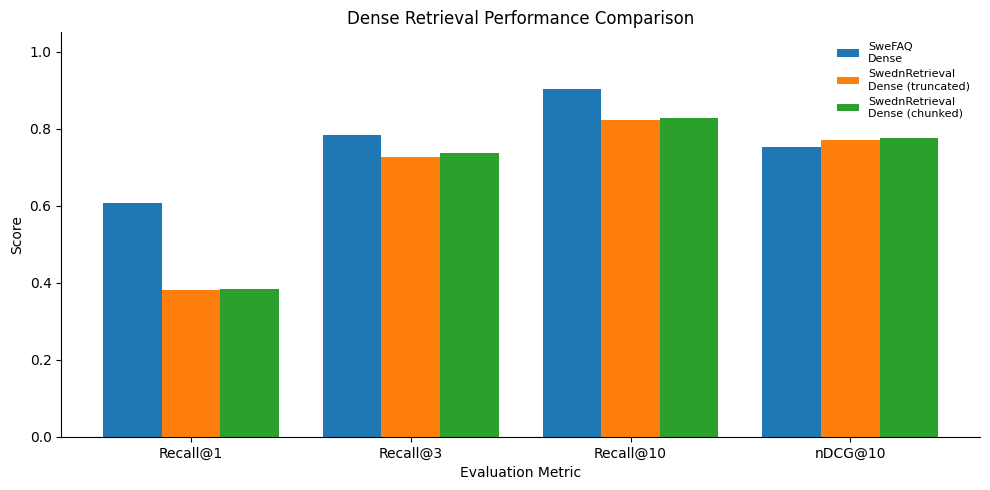

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Recall@1", "Recall@3", "Recall@10", "nDCG@10"]

plot_data = comparison.set_index(["Dataset", "Method"])[metrics]

labels = [
    f"{dataset}\n{method}"
    for dataset, method in plot_data.index
]

x = np.arange(len(metrics))
width = 0.8 / len(plot_data)

fig, ax = plt.subplots(figsize=(10, 5))

for i, (label, row) in enumerate(plot_data.iterrows()):
    ax.bar(
        x - 0.4 + width / 2 + i * width,
        row.values,
        width,
        label=labels[i]
    )

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_title("Dense Retrieval Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

# Example

In [ ]:
def show_example_dense(query_idx, queries, corpus_ids, corpus_texts, embeddings, qrels_dict, model, k=10):
    q = queries[query_idx]
    qid = q["_id"]
    query_text = q["text"]

    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    scores = (embeddings @ query_emb.T).flatten()
    top_indices = scores.argsort()[::-1][:k]

    relevant_ids = qrels_dict.get(qid, set())

    print("QUERY:", query_text)
    print("RELEVANT (gold) IDs:", relevant_ids)
    print()
    print(f"TOP-{k} RETRIEVED (Dense):")
    for rank, idx in enumerate(top_indices, start=1):
        doc_id = corpus_ids[idx]
        is_correct = "CORRECT" if doc_id in relevant_ids else ""
        print(f"{rank}. id={doc_id} score={scores[idx]:.4f} {is_correct}")
        print(f"   {corpus_texts[idx][:150]}")
    print("-"*80)

In [ ]:
# SweFAQ example
show_example_dense(
    query_idx=0,
    queries=swefaq_queries,
    corpus_ids=swefaq_corpus_ids,
    corpus_texts=swefaq_corpus_texts,
    embeddings=swefaq_embeddings,
    qrels_dict=swefaq_qrels_dict,
    model=model
)

QUERY: Får jag lägre föräldrapenning om jag går ner i arbetstid innan förlossningen?
RELEVANT (gold) IDs: {'2'}

TOP-10 RETRIEVED (Dense):
1. id=2 score=0.9204 CORRECT
   passage: Nej, inte om det är 6 månader eller kortare tid kvar till den planerade förlossningen. Din föräldrapenning beräknas på den inkomst du hade in
2. id=4 score=0.8886 
   passage: Nej, inte om du meddelar det minst två månader i förväg. Enligt lag har du rätt att vara föräldraledig när du tar ut föräldrapenning. När du 
3. id=147 score=0.8848 
   passage: Ja, du har rätt att förkorta din arbetstid med upp till 25 procent om du eller en annan förälder får vårdbidrag för barnet. Det gäller även e
4. id=48 score=0.8832 
   passage: Ja. När du börjar arbeta efter en föräldraledig period och sedan bestämmer du dig för att vara föräldraledig och ta ut föräldrapenning, ska d
5. id=25 score=0.8810 
   passage: Ja, om du skulle ha arbetat under den period du ansöker om graviditetspenning.
6. id=117 score=0.8809 
   passag

In [ ]:
test_queries = [
    "Får jag pengar för lördagar och söndagar?",
    "Kan jag ansöka på webben om jag har skyddad identitet?"
]

for tq in test_queries:
    tq_norm = tq.strip().lower()
    match_idx = None
    for idx, q in enumerate(swefaq_queries):
        if q["text"].strip().lower() == tq_norm:
            match_idx = idx
            break
    if match_idx is None:
        # fallback: substring match, in case of punctuation/whitespace differences
        for idx, q in enumerate(swefaq_queries):
            if tq_norm[:30] in q["text"].strip().lower():
                match_idx = idx
                break
    if match_idx is None:
        print(f"\n!!! NOT FOUND in swefaq_queries: {tq!r} — check exact spelling/whitespace")
        continue
    print(f"\n=== Query index {match_idx} ===")
    show_example_dense(match_idx, swefaq_queries, swefaq_corpus_ids, swefaq_corpus_texts, swefaq_embeddings, swefaq_qrels_dict, model)


=== Query index 4 ===
QUERY: Får jag pengar för lördagar och söndagar?
RELEVANT (gold) IDs: {'11'}

TOP-10 RETRIEVED (Dense):
1. id=11 score=0.8855 CORRECT
   passage: Ja, om du skulle ha arbetat lördag och söndag så kan du få ersättning även för dessa dagar.
2. id=376 score=0.8506 
   passage: Ja. Du kan till exempel inte arbeta måndag, tisdag och onsdag och vara sjukskriven torsdag och fredag. Det går ibland att göra undantag från 
3. id=79 score=0.8417 
   passage: Nej. Det räcker att du uppfyller villkoren för att få bidraget.
4. id=215 score=0.8408 
   passage: Ja. Du kan få pengar för hel, tre fjärdedels, halv, en fjärdedels eller en åttondels dag.  Dela antalet timmar som du avstått från att arbeta
5. id=574 score=0.8403 
   passage: Nej. Om du däremot har barn som bor hos dig större delen av tiden, så kan du ha rätt till det särskilda bidraget för hemmavarande barn. Om du
6. id=121 score=0.8400 
   passage: Nej. Båda föräldrarna kan inte få ersättning för samma barn och tid.
7

In [ ]:
# SwednRetrieval
show_example_dense(
    query_idx=0,
    queries=swedn_queries,
    corpus_ids=swedn_corpus_ids,
    corpus_texts=swedn_corpus_texts,
    embeddings=swedn_embeddings,
    qrels_dict=swedn_qrels_dict,
    model=model
)

QUERY: Många unga skadas på cykel och moped
RELEVANT (gold) IDs: {'train_2', 'train_1'}

TOP-10 RETRIEVED (Dense):
1. id=train_1 score=0.9025 CORRECT
   passage: Långt fler tonåringar skadar sig på mopeder och cyklar än när de sitter i bil eller andra fordon, enligt ny statistik.
2. id=train_2 score=0.8951 CORRECT
   passage: Mellan 2011 och 2015 blev 1 076 tonåringar i åldrarna 14–17 år måttligt eller allvarligt skadade när de körde moped. Under samma period skada
3. id=train_1067 score=0.8342 
   passage: Lekplatser är ett naturligt ställe för bus, skoj och lek – men också en av de vanligaste olycksplatserna. Socialstyrelsen har på Dagens Nyhet
4. id=test_541 score=0.8336 
   passage: Gående är oskyddade i trafiken och cykel räknas som ett fordon.
5. id=train_1601 score=0.8327 
   passage: DN har tidigare berättat om ungdomsrån i olika delar av Stockholm, där unga – ofta minderåriga – stulit bland annat jackor, hörlurar och tele
6. id=train_2669 score=0.8311 
   passage: I tisdags ka

In [ ]:
swedn_test_queries = [
    "Nylander hetaste svensken i draften",
    "Backe till Rosenborg",
    "Ekonom: Avtalet innebär rundgång"
]

for tq in swedn_test_queries:
    tq_norm = tq.strip().lower()
    match_idx = None
    for idx, q in enumerate(swedn_queries):
        if q["text"].strip().lower() == tq_norm:
            match_idx = idx
            break
    if match_idx is None:
        for idx, q in enumerate(swedn_queries):
            if tq_norm[:20] in q["text"].strip().lower():
                match_idx = idx
                break
    if match_idx is None:
        print(f"\n!!! NOT FOUND in swedn_queries: {tq!r} — check exact spelling/whitespace")
        continue
    print(f"\n=== Query index {match_idx} ===")
    show_example_dense(match_idx, swedn_queries, swedn_corpus_ids, swedn_corpus_texts, swedn_embeddings, swedn_qrels_dict, model)


=== Query index 9 ===
QUERY: Nylander hetaste svensken i draften
RELEVANT (gold) IDs: {'train_29', 'train_28'}

TOP-10 RETRIEVED (Dense):
1. id=train_29 score=0.8653 CORRECT
   passage: Gångna säsongen har varit succéartad för den unge hockeyforwarden Alexander Nylander. Eller vad sägs om totalt 87 poäng, varav 75 i grundseri
2. id=train_28 score=0.8434 CORRECT
   passage: En svensk väntas gå tidigt i NHL-draften. Alexander Nylander, 18. – Tror jag kommer vara lite nervös, säger han till NHL:s webbplats.
3. id=validation_1543 score=0.8243 
   passage: Spekulationerna om vilka som skulle få spela huvudrollerna när Millenniumserien filmatiseras har varit många. Nu är det klart att Lisbeth Sal
4. id=train_665 score=0.8230 
   passage: Norge ställer upp med tre stafettdebutanter i fredagens herrstafett. Niklas Dyrhaug, Didrik Toenseth och Anders Gloersen kör de tre första st
5. id=train_659 score=0.8223 
   passage: En halvtimmas bilfärd utanför Philadelphia, i ett mycket välskött villaom